a =  0.8920484860803973  b =  -8.388949997247533


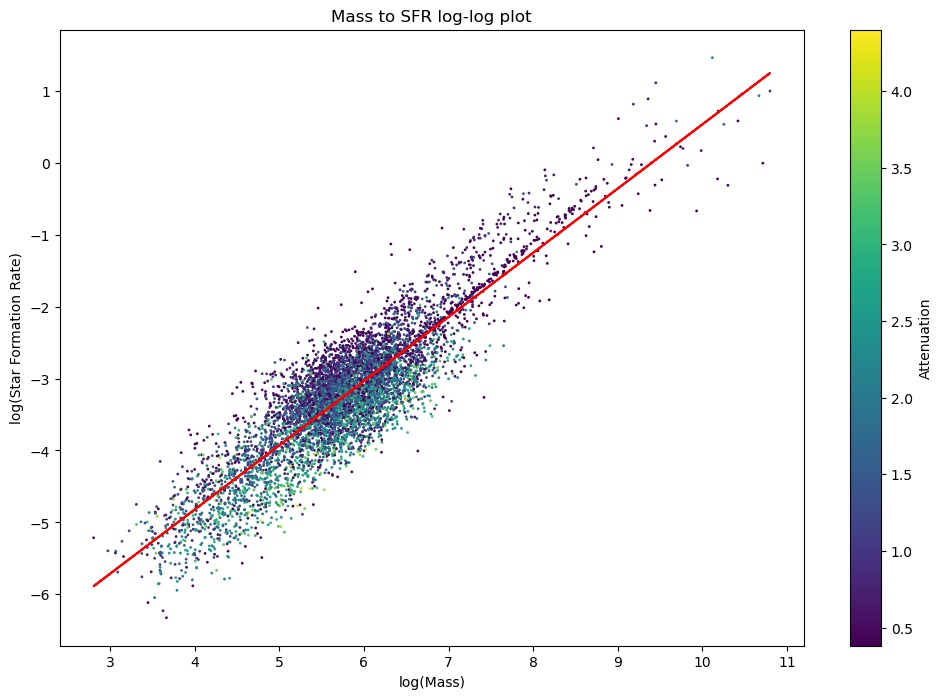

In [2]:
from astropy.io import fits
from astropy.table import Table
import matplotlib.pyplot as plt
import numpy as np

results = fits.open('results.fits')

table = Table(results[1].data)

mass = table['bayes.stellar.m_star']
sfr = table['bayes.sfh.sfr']
attenuation = table['bayes.attenuation.Av_BC']

log_mass = np.log10(mass)
log_sfr = np.log10(sfr)

a, b = np.polyfit(log_mass, log_sfr, 1)

linear_fit = a*log_mass + b

print("a = ", a, " b = ",  b)

plt.figure(figsize=(12, 8)) 
scatter = plt.scatter(log_mass, log_sfr, s=1, c=attenuation, cmap='viridis')
cbar = plt.colorbar(scatter)  
cbar.set_label('Attenuation')
plt.plot(log_mass, linear_fit, color = "red")
plt.xlabel('log(Mass)')
plt.ylabel('log(Star Formation Rate)')
plt.title('Mass to SFR log-log plot')
plt.show()

I got a linear fit with: a =0.892, b =-8.389

The formula from Speagle 2014 is:

$$
\log \psi(M^*, t) = 
\big(0.96 \pm 0.05 - (0.045 \pm 0.006) \cdot t \big) \log M^* 
- \big(7.41 \pm 0.48 - (0.27 \pm 0.06) \cdot t \big)
$$

I will derive t from redshift median from my probe:

Age of the Universe at median z=0.200 is 11.275 Gyr


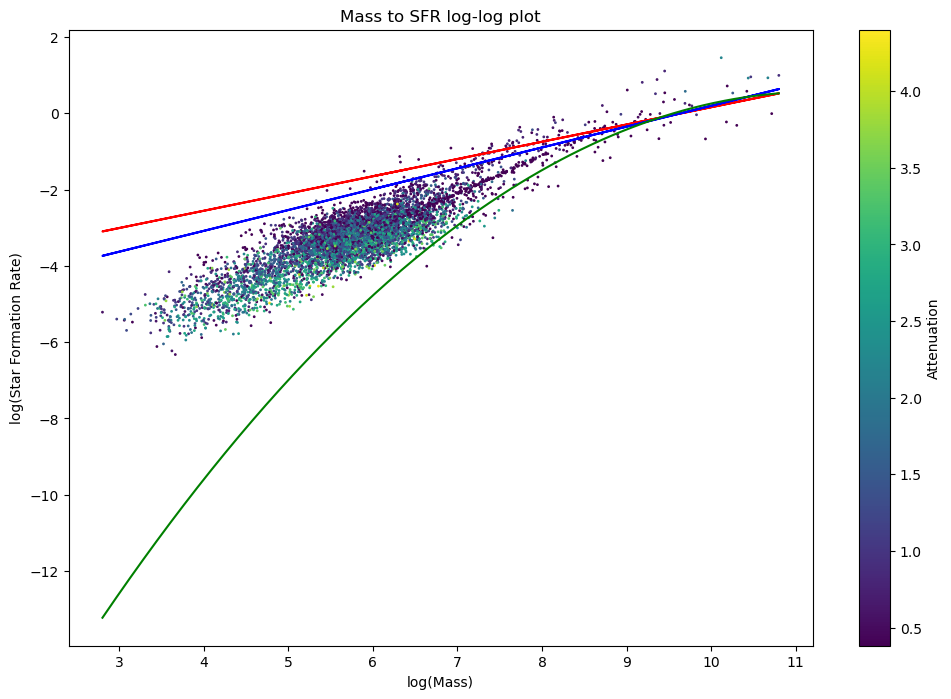

In [3]:
import statistics
from astropy.cosmology import Planck18

redshift = table['bayes.universe.redshift']
redshift_median = statistics.median(redshift)

t = Planck18.age(redshift_median)

print(f"Age of the Universe at median z={redshift_median:.3f} is {t:.3f}")

a2 = 0.96 - 0.045 * t.value
b2 = 7.41 - 0.27 * t.value

linear_fit2 = a2 * log_mass - b2

a3 = 0.84 - 0.026 * t.value
b3 = 6.51 - 0.11 * t.value

linear_fit3 = a3 * log_mass - b3

# Popesso 2023 
# log(SFR) = (a1 t + b1) log(M) + b2 log^2 (M) + (b0 + a0 t)
a0 = 0.20
a1 = -0.034
b0 = -26.134
b1 = 4.722
b2 = -0.1925

x_model = np.linspace(min(log_mass), max(log_mass), 200)

log_sfr_model = (a1 * t.value + b1) * x_model + b2 * (x_model**2) + (b0 + a0 * t.value)

plt.figure(figsize=(12, 8)) 
scatter = plt.scatter(log_mass, log_sfr, s=1, c=attenuation, cmap='viridis')
cbar = plt.colorbar(scatter)  
cbar.set_label('Attenuation')
plt.plot(log_mass, linear_fit2, color = "red", label="Speagle 2014")
plt.plot(log_mass, linear_fit3, color = "blue", label="Speagle 2014")
plt.plot(x_model, log_sfr_model, color="green", label = "Popesso 2023")
plt.xlabel('log(Mass)')
plt.ylabel('log(Star Formation Rate)')
plt.title('Mass to SFR log-log plot')
plt.show()

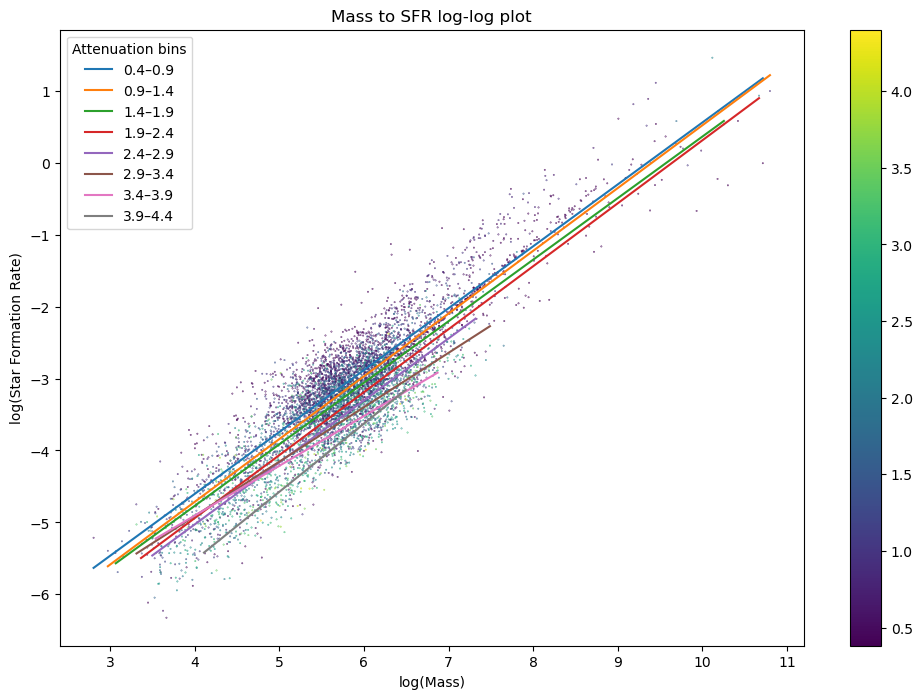

In [4]:
# zakres attenuacji
att_min = np.nanmin(attenuation)
att_max = np.nanmax(attenuation)

bins = np.arange(att_min, att_max, 0.5)

plt.figure(figsize=(12, 8)) 
for i in range(len(bins)-1):
    lower = bins[i]
    upper = bins[i+1]
    
    # maska wybierająca punkty z danego przedziału
    mask = (attenuation >= lower) & (attenuation < upper)
    
    # pomijamy jeśli za mało punktówa
    if np.sum(mask) < 10:
        continue
    
    x = log_mass[mask]
    y = log_sfr[mask]
    
    # dopasowanie liniowe
    a, b = np.polyfit(x, y, 1)
    
    # sortowanie do ładnej linii
    x_sorted = np.sort(x)
    y_fit = a * x_sorted + b
    
    # rysowanie
    plt.plot(x_sorted, y_fit, label=f"{lower:.1f}–{upper:.1f}")

plt.legend(title="Attenuation bins")
scatter = plt.scatter(log_mass, log_sfr, s=0.1, c=attenuation, cmap='viridis')
cbar = plt.colorbar(scatter) 
plt.xlabel('log(Mass)')
plt.ylabel('log(Star Formation Rate)')
plt.title('Mass to SFR log-log plot')
plt.show()


Widać na wykresie że istnieje związek atenuacji z stosunkiem log(SFR) log(Mass), ciężej jest określić atenuacje patrząc tylko na miejsce galaktyki na wykresie. Dużo punktów o małej atenuacji szczególnie jest rozłożonych chaotycznie. Pomysł: zrobić scatterplot tylko dla tych punktów które mają dużą atenuacje, małą atenuacje, może uda się określić że jeżeli punkt jest w x to jest duże prawdopodobieństwo że ma dużą atenuację, małą etc.

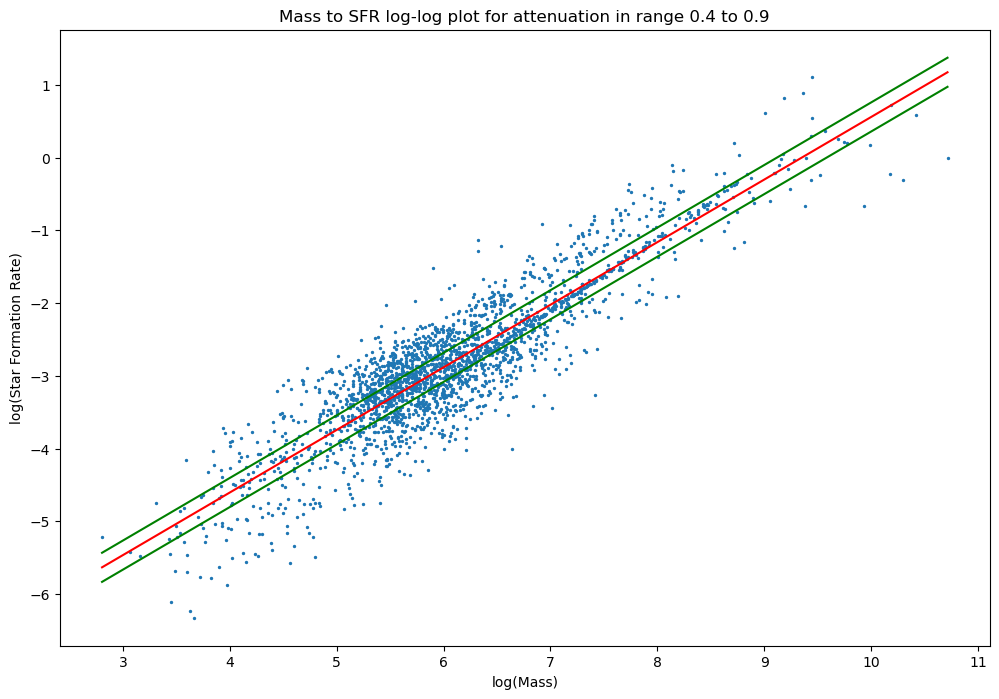

For attenuation from 0.4 to 0.9 the coefficients are a = 0.86 and b = -8.04


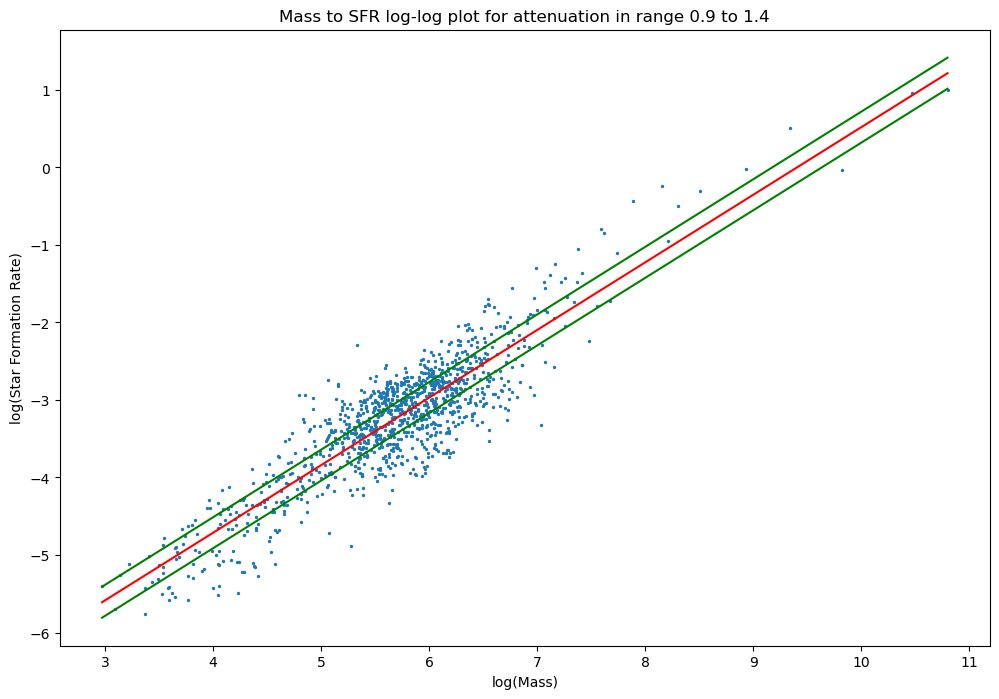

For attenuation from 0.9 to 1.4 the coefficients are a = 0.87 and b = -8.20


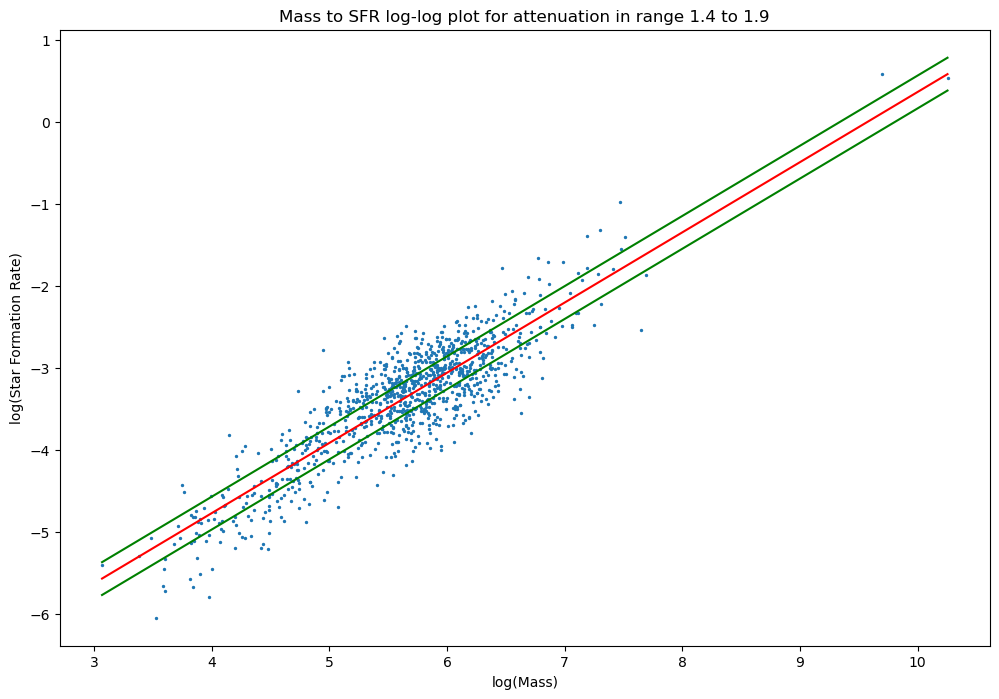

For attenuation from 1.4 to 1.9 the coefficients are a = 0.86 and b = -8.19


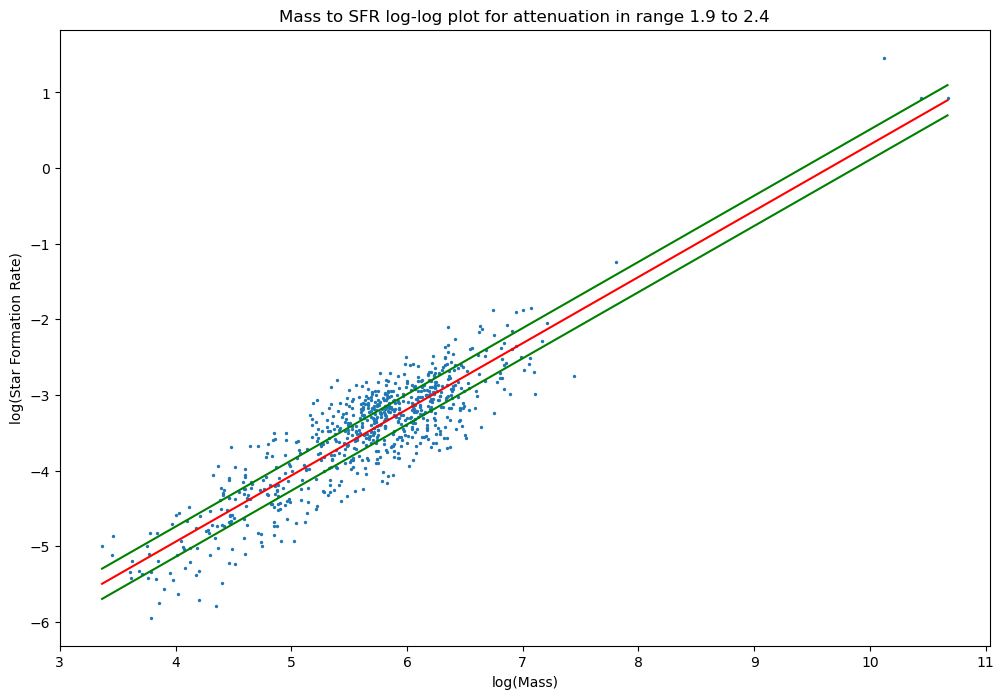

For attenuation from 1.9 to 2.4 the coefficients are a = 0.87 and b = -8.44


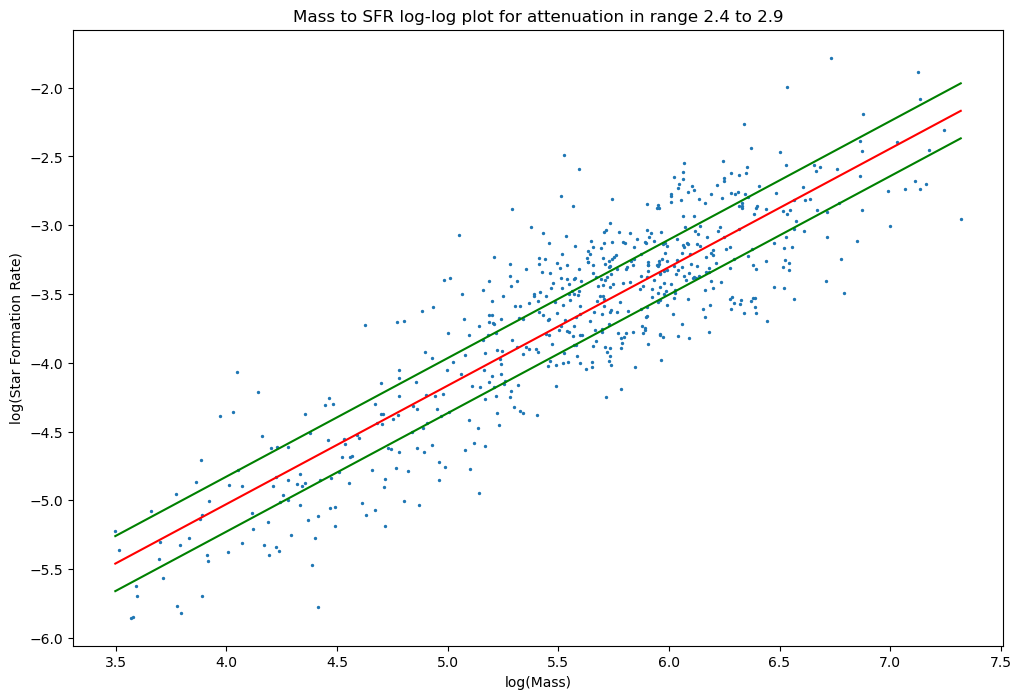

For attenuation from 2.4 to 2.9 the coefficients are a = 0.86 and b = -8.47


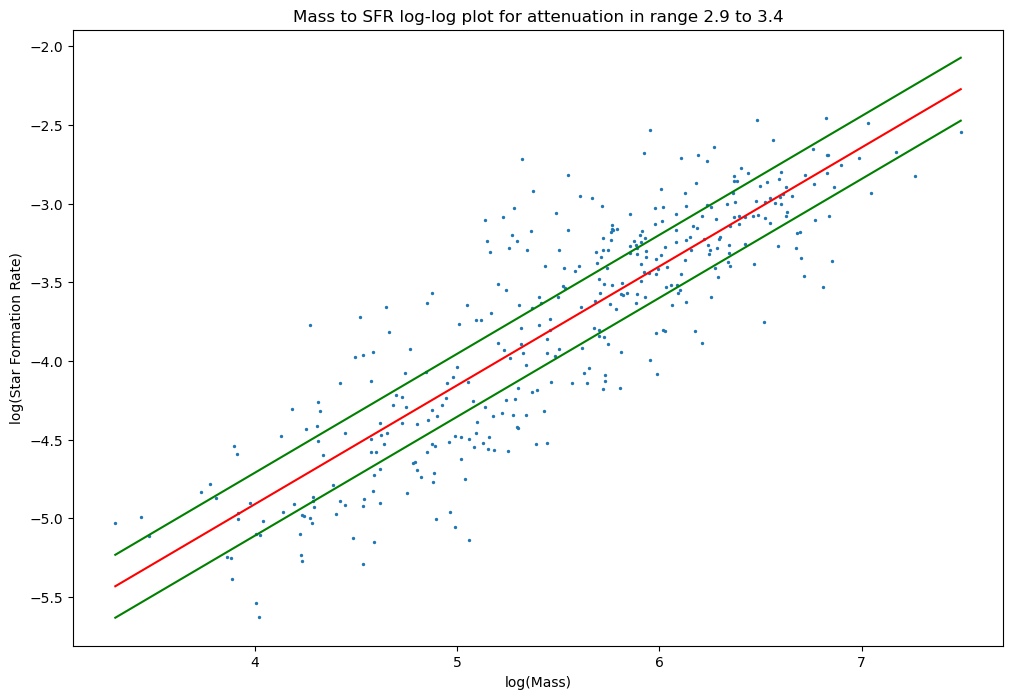

For attenuation from 2.9 to 3.4 the coefficients are a = 0.76 and b = -7.94


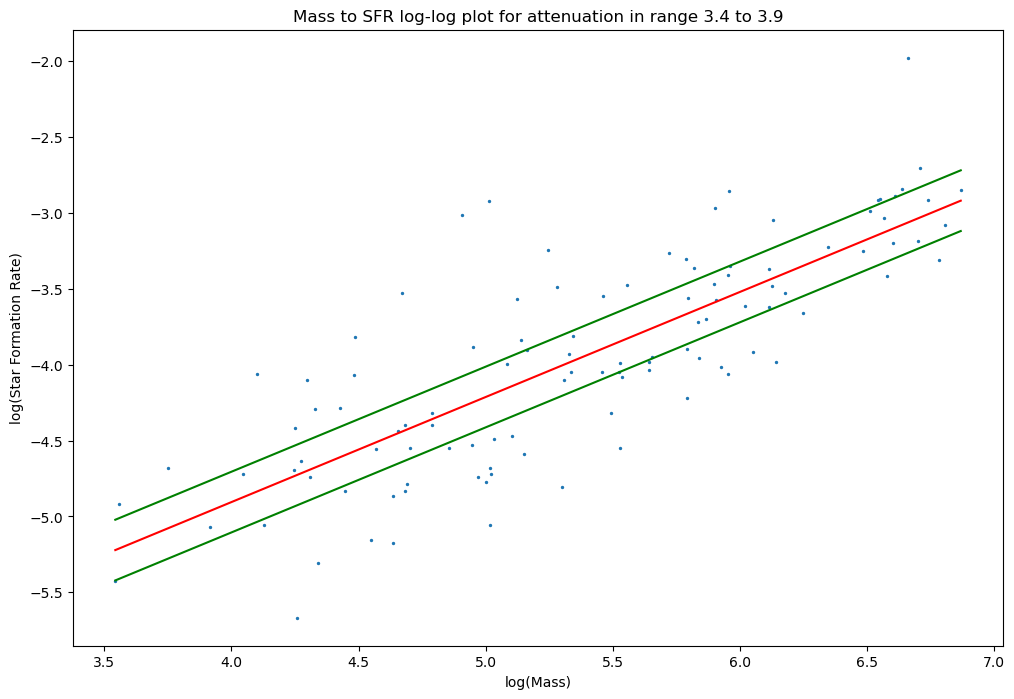

For attenuation from 3.4 to 3.9 the coefficients are a = 0.69 and b = -7.67


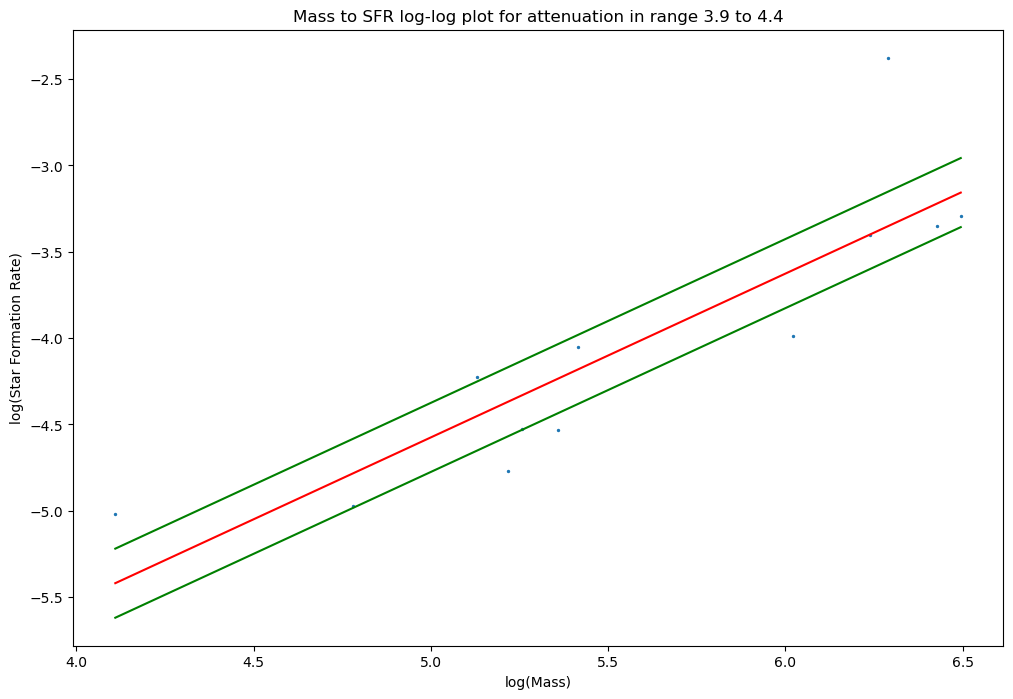

For attenuation from 3.9 to 4.4 the coefficients are a = 0.95 and b = -9.32


In [5]:
# zakres attenuacji
att_min = np.nanmin(attenuation)
att_max = np.nanmax(attenuation)

bins = np.arange(att_min, att_max, 0.5)

for i in range(len(bins)-1):
    lower = bins[i]
    upper = bins[i+1]
    
    # maska wybierająca punkty z danego przedziału
    mask = (attenuation >= lower) & (attenuation < upper)
    
    # pomijamy jeśli za mało punktówa
    if np.sum(mask) < 10:
        continue
    
    x = log_mass[mask]
    y = log_sfr[mask]
    z = attenuation[mask]
    
    # dopasowanie liniowe
    a, b = np.polyfit(x, y, 1)
    
    # sortowanie do ładnej linii
    x_sorted = np.sort(x)
    y_fit = a * x_sorted + b
    
    # rysowanie
    plt.figure(figsize=(12, 8)) 
    scatter = plt.scatter(x, y, s=2)
    plt.plot(x_sorted, y_fit, color="red")
    plt.plot(x_sorted, y_fit - 0.2, color="green")
    plt.plot(x_sorted, y_fit + 0.2, color="green")
    plt.xlabel('log(Mass)')
    plt.ylabel('log(Star Formation Rate)')
    plt.title(f'Mass to SFR log-log plot for attenuation in range {lower:.1f} to {upper:.1f}')
    plt.show()
    print(f'For attenuation from {lower:.1f} to {upper:.1f} the coefficients are a = {a:.2f} and b = {b:.2f}')

1. For attenuation from 0.4 to 0.9 the coefficients are a = 0.86 and b = -8.04
2. For attenuation from 0.9 to 1.4 the coefficients are a = 0.87 and b = -8.20
3. For attenuation from 1.4 to 1.9 the coefficients are a = 0.86 and b = -8.19
4. For attenuation from 1.9 to 2.4 the coefficients are a = 0.87 and b = -8.44
5. For attenuation from 2.4 to 2.9 the coefficients are a = 0.86 and b = -8.47
6. For attenuation from 2.9 to 3.4 the coefficients are a = 0.76 and b = -7.94
7. For attenuation from 3.4 to 3.9 the coefficients are a = 0.69 and b = -7.67
8. For attenuation from 3.9 to 4.4 the coefficients are a = 0.95 and b = -9.32

Ostatni kubełek ma za mało punktów aby uznać go za statystycznie znaczący. Poza tym kubełki 1 - 5 mają ten sam czynnik a. Kubełki 2 i 3 oraz 4 i 5 są prawie takie same patrząc na współczynniki. Kubełki 1, 23, 45 można rozpoznać po b, różnice w b są rzędu 0.2, niestety jest to mało patrząc na odległości punktów od lini.

Liczba punktów w odległości < 0.7 : 5614 liczba punktów w całości to: 6276


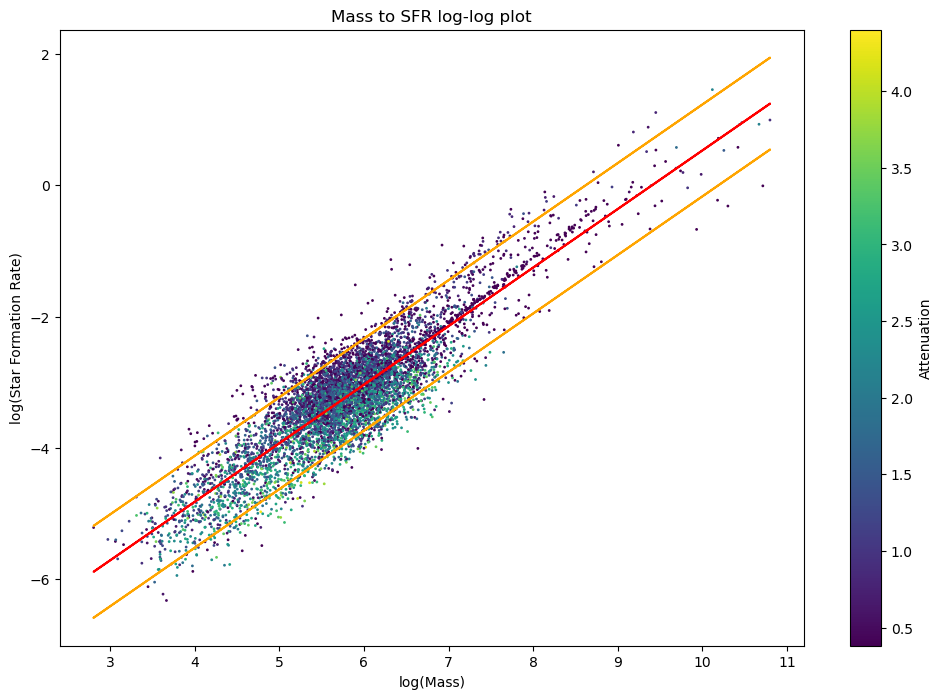

In [6]:
# Kod do liczenia odległości od lini

d = 0.7 # odległośc od lini

a, b = np.polyfit(log_mass, log_sfr, 1)

linear_fit = a*log_mass + b

# odległość od linii
dist = np.abs(log_sfr - linear_fit)

# ile punktów spełnia warunek
count = np.sum(dist < d)
total_count = np.size(linear_fit)

print("Liczba punktów w odległości <", d, ":", count, "liczba punktów w całości to:", total_count)

plt.figure(figsize=(12, 8)) 
scatter = plt.scatter(log_mass, log_sfr, s=1, c=attenuation, cmap='viridis')
cbar = plt.colorbar(scatter)  
cbar.set_label('Attenuation')
plt.plot(log_mass, linear_fit, color = "red")
plt.plot(log_mass, linear_fit - d, color = "orange")
plt.plot(log_mass, linear_fit + d, color = "orange")
plt.xlabel('log(Mass)')
plt.ylabel('log(Star Formation Rate)')
plt.title('Mass to SFR log-log plot')
plt.show()

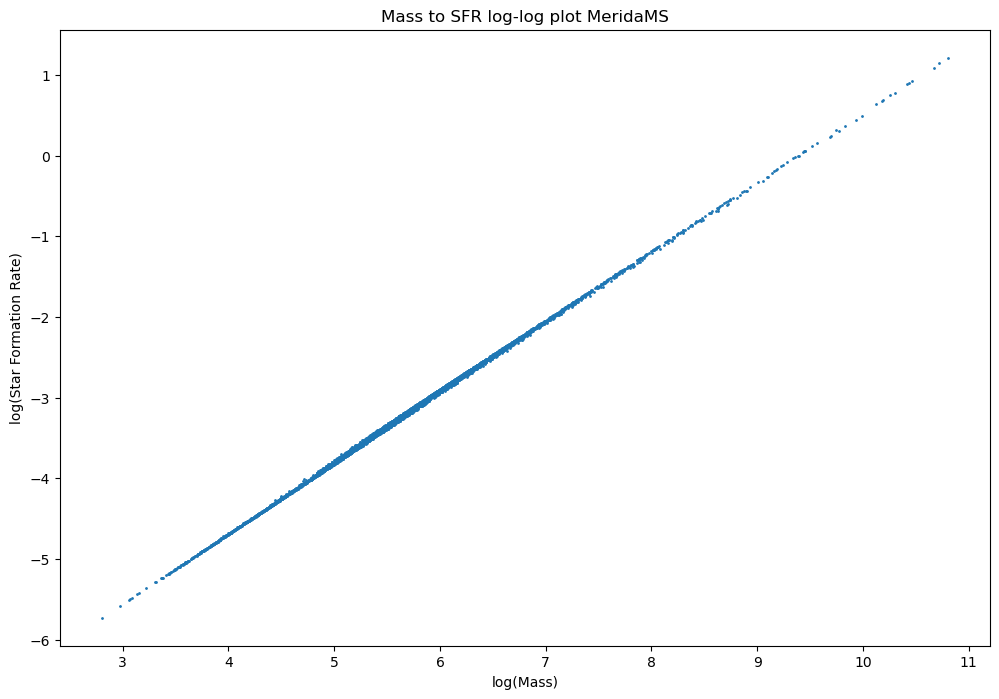

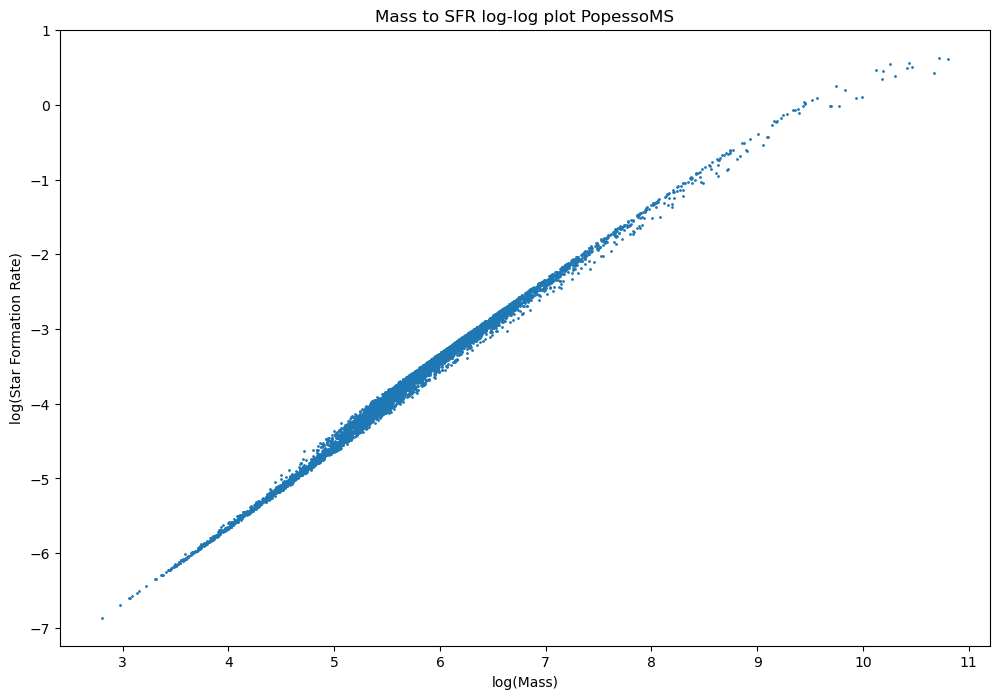

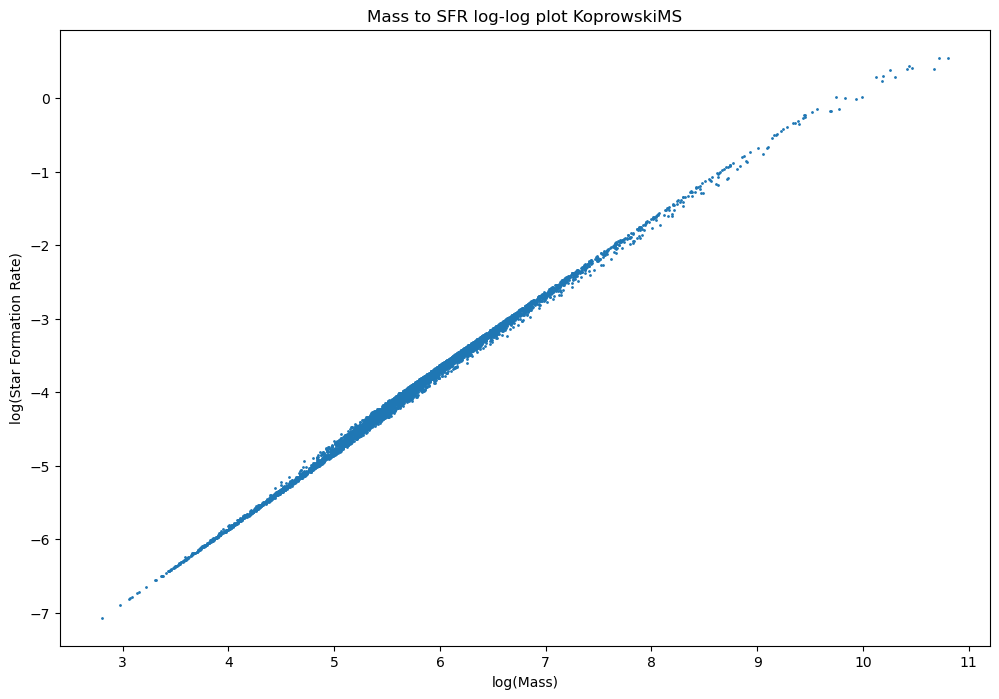

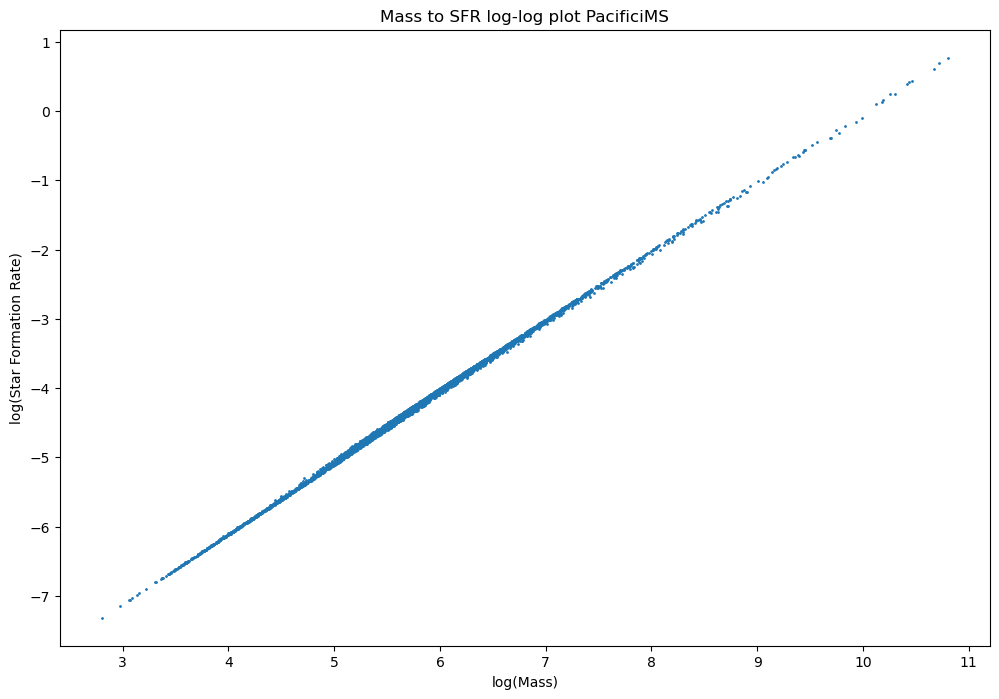

In [10]:
from astropy.cosmology import LambdaCDM

cosmo = LambdaCDM(H0 = 70, Om0= 0.3, Ode0= 0.7)

def MeridaMS(logM, z):
    """
    Give mass and redshift, get SFR
    :param M: Log(Mass) in solar masses
    :param z: Redshift
    :return: Log(SFR) in solar masses/yr
    """
    zPaper = np.array([0.0, 0.0625, 0.125, 0.1875, 0.25, 0.3125, 0.375,
                  0.4375, 0.5, 0.5625, 0.625, 0.6875, 0.75, 0.8125,
                  0.875, 0.9375, 1.0, 1.0625, 1.125, 1.1875,
                  1.25, 1.75, 2.25, 2.75, 3.5, 4.5, 6, 8.0,
                  8.5, 9.0, 9.5, 10.0, 10.5, 11.0, 11.5, 12.0, 12.5,
                  13.0, 13.5, 14.0, 14.5, 15.0, 15.5, 16.0, 16.5, 17.0,
                  17.5, 18.0, 18.5, 19.0, 19.5, 20.0])
    alphaPaper = np.array([-8.15625000000003, -8.13460937500003, -8.11218750000003,
                      -8.08898437500003, -8.06500000000003, -8.04023437500003,
                      -8.01468750000003, -7.988359375000028, -7.961250000000027,
                      -7.933359375000027, -7.904687500000026, -7.8752343750000255,
                      -7.8450000000000255, -7.813984375000024, -7.782187500000024,
                      -7.749609375000023, -7.716250000000022, -7.682109375000021,
                      -7.647187500000021, -7.611484375000019, -7.57, -7.27, -6.87,
                      -6.47, -6.33, -7.03, -7.75, -8.45, -8.578571428571419,
                      -8.688571428571416, -8.779999999999987, -8.852857142857129, -8.90714285714284,
                      -8.942857142857125, -8.96, -8.96,-8.96,
                      -8.96,-8.96,-8.96,-8.96,-8.96,-8.96,-8.96,-8.96,
                      -8.96,-8.96,-8.96,-8.96,-8.96,-8.96,-8.96,])
    betaPaper = np.array([0.8636250000000004, 0.8627109375000006, 0.8617187500000006,
                     0.8606484375000009, 0.8595000000000009, 0.8582734375000011,
                     0.8569687500000012, 0.8555859375000012, 0.8541250000000014,
                     0.8525859375000013, 0.8509687500000014, 0.8492734375000015,
                     0.8475000000000015, 0.8456484375000015, 0.8437187500000016,
                     0.8417109375000016, 0.8396250000000016, 0.8374609375000016,
                     0.8352187500000016, 0.8328984375000016, 0.83, 0.81, 0.78,
                     0.75, 0.75, 0.85, 0.93, 1.02,
                     1.0395238095238082, 1.0578571428571413, 1.0749999999999982,
                     1.090952380952379, 1.1057142857142832, 1.1192857142857116,
                     1.1316666666666637, 1.1428571428571395, 1.152857142857139,
                     1.1616666666666626, 1.16928571428571, 1.1757142857142808,
                     1.1809523809523756, 1.184999999999994, 1.1878571428571365,
                     1.1895238095238025, 1.1899999999999924, 1.189285714285706,
                     1.1873809523809435, 1.1842857142857048, 1.17999999999999,
                     1.1745238095237989, 1.1678571428571312, 1.1599999999999877])

    alphaInterp = np.interp(z,
                            zPaper,
                            alphaPaper)
    betaInterp = np.interp(z,
                            zPaper,
                            betaPaper)
    logSFR = betaInterp*logM + alphaInterp
    return logSFR

def PopessoMS(logM, z, IMF = 'C'):
    """
    Give mass and redshift, get SFR
    :param logM: Mass in solar masses
    :param z: Redshift
    :param IMF: C for chabrier, S for Salpeter, K for Kroupa
    :return: Log(SFR) in solar masses/yr
    """
    a0 = 2.71
    a1 = -0.186
    a2 = 10.86
    a3 = -0.0729


    age = cosmo.age(z).value

    logSFR = a0 + a1*age -np.log10(1 + 1/(10**logM/10**(a2+a3*age)))
    if IMF == 'K':
        return logSFR
    logSFR = np.log10(10**logSFR/0.67)
    if IMF == 'S':
        return logSFR
    logSFR = np.log10(10 ** logSFR*0.63)
    if IMF == 'C':
        return logSFR

    raise ValueError('Wrong IMF type!')

def KoprowskiMS(logM, z, IMF = 'C'):
    """
    Give mass and redshift, get SFR
    :param M: Log(Mass) in solar masses
    :param z: Redshift
    :param IMF: C for chabrier, S for Salpeter, K for Kroupa
    :return: Log(SFR) in solar masses/yr
    """
    a1 = 2.97
    a2 = -2.62
    a3 = 0.59
    b1 = 11.38
    b2 = -1.14
    b3 = 0.5

    sfrMax = 10**(a1 + a2*np.exp(-a3*z))
    M0 = 10**(b1 + b2*np.exp(-b3*z))

    SFR = sfrMax/(1+M0/10**logM)
    logSFR = np.log10(SFR)
    if IMF == 'C':
        return logSFR
    ValueError('Wrong IMF type! Write it you lazy dong!')

def PacificiMS(logM, z, QGLim = False, IMF = 'C'):
    """
    Give mass and redshift, get SFR
    :param M: Log(Mass) in solar masses
    :param z: Redshift
    :param QGLim: if True, returns limit for quiescence
    :param IMF: C for chabrier, S for Salpeter, K for Kroupa
    :return: Log(SFR) in solar masses/yr
    """
    cosmicAge = cosmo.age(z).value
    if QGLim:
        tau = np.log10(0.2 / (cosmicAge * 1e9))
    else:
        tau = np.log10(1 / (cosmicAge * 1e9))
    logSFR = tau+logM

    if IMF == 'C':
        return logSFR
    ValueError('Wrong IMF type! Write it you lazy dong!')


z = table['bayes.universe.redshift']


functions = [MeridaMS, PopessoMS, KoprowskiMS, PacificiMS]

for name, f in enumerate(functions):

    log_sfr_MS = f(log_mass, z)

    plt.figure(figsize=(12, 8)) 
    scatter = plt.scatter(log_mass, log_sfr_MS, s=1)
    plt.xlabel('log(Mass)')
    plt.ylabel('log(Star Formation Rate)')
    plt.title(f'Mass to SFR log-log plot {f.__name__}')
    plt.show()